In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!nvidia-smi

Wed Nov 18 18:05:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("Token loaded ✅")

Token loaded ✅


In [3]:
!pip install -q --upgrade kaggle

In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   85M  113G   1% /


In [4]:
!kaggle datasets download -d awsaf49/brats20-dataset-training-validation -p /content
!ls -lh /content

Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
License(s): CC0-1.0
100% 4.16G/4.16G [00:52<00:00, 84.9MB/s]

total 4.2G
-rw-r--r-- 1 root root 4.2G Jul  2  2020 brats20-dataset-training-validation.zip
drwx------ 6 root root 4.0K Nov 19 14:25 drive
drwxr-xr-x 1 root root 4.0K Nov 17 17:03 sample_data


In [5]:
!unzip -q /content/brats20-dataset-training-validation.zip "BraTS2020_TrainingData/*" -d /content/brats

In [8]:
import os

root = "/content/brats/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
patients = sorted([p for p in os.listdir(root) if p.startswith("BraTS20")])
print("Patients:", len(patients))

for p in patients:
    files = os.listdir(f"{root}/{p}")
    if f"{p}_seg.nii" not in files:
        print("⚠️ Seg missing/peyar vera:", p, files)

Patients: 369
⚠️ Seg missing/peyar vera: BraTS20_Training_355 ['BraTS20_Training_355_flair.nii', 'BraTS20_Training_355_t1ce.nii', 'BraTS20_Training_355_t2.nii', 'W39_1998.09.19_Segm.nii', 'BraTS20_Training_355_t1.nii']


In [9]:
old = f"{root}/BraTS20_Training_355/W39_1998.09.19_Segm.nii"
new = f"{root}/BraTS20_Training_355/BraTS20_Training_355_seg.nii"

if os.path.exists(old):
    os.rename(old, new)
    print("Renamed ✅")

Renamed ✅


In [10]:
import os

root = "/content/brats/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
patients = sorted([p for p in os.listdir(root) if p.startswith("BraTS20")])
print("Patients:", len(patients))

for p in patients:
    files = os.listdir(f"{root}/{p}")
    if f"{p}_seg.nii" not in files:
        print("⚠️ Seg missing/peyar vera:", p, files)

Patients: 369


In [11]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

MODALITIES = ["flair", "t1", "t1ce", "t2"]

def normalize(vol):
    brain = vol > 0                          # brain voxels mattum (True/False map)
    mean = vol[brain].mean()
    std = vol[brain].std()
    out = np.zeros_like(vol, dtype=np.float32)
    out[brain] = (vol[brain] - mean) / std   # z = (x − μ) ÷ σ
    return out

def load_patient(p):
    folder = f"{root}/{p}"
    scans = []
    for m in MODALITIES:
        vol = nib.load(f"{folder}/{p}_{m}.nii").get_fdata()
        scans.append(normalize(vol))
    image = np.stack(scans, axis=0)          # 4 scans → (4, 240, 240, 155)

    seg = nib.load(f"{folder}/{p}_seg.nii").get_fdata().astype(np.uint8)
    seg[seg == 4] = 3                        # labels: 0,1,2,4 → 0,1,2,3

    image = image[:, 56:184, 56:184, 13:141] # crop
    seg = seg[56:184, 56:184, 13:141]
    return image, seg

image, seg = load_patient("BraTS20_Training_001")

print("Image shape:", image.shape)
print("Seg shape  :", seg.shape)
print("Seg labels :", np.unique(seg))
flair = image[0]
print(f"FLAIR brain mean: {flair[flair != 0].mean():.3f}, std: {flair[flair != 0].std():.3f}")
print("Tumour voxels after crop:", np.sum(seg > 0))

Image shape: (4, 128, 128, 128)
Seg shape  : (128, 128, 128)
Seg labels : [0 1 2 3]
FLAIR brain mean: 0.044, std: 1.035
Tumour voxels after crop: 211033


In [12]:
from tqdm import tqdm

out_dir = "/content/preprocessed"
os.makedirs(out_dir, exist_ok=True)          # folder create (irundhaa paravaayilla)

crop_loss = []

for p in tqdm(patients):
    image, seg = load_patient(p)
    np.save(f"{out_dir}/{p}_image.npy", image.astype(np.float16))
    np.save(f"{out_dir}/{p}_seg.npy", seg)

    # crop evvalavu tumour-ai vettudhu?
    full_seg = nib.load(f"{root}/{p}/{p}_seg.nii").get_fdata()
    full = np.sum(full_seg > 0)
    kept = np.sum(seg > 0)
    crop_loss.append((p, 100 * (full - kept) / full))

losses = np.array([l for _, l in crop_loss])
print(f"\nAverage crop loss: {losses.mean():.3f} %")
print(f"Max crop loss    : {losses.max():.3f} %")
print(f"Patients with > 1% loss: {np.sum(losses > 1)}")

print("\nWorst 5:")
for p, l in sorted(crop_loss, key=lambda x: x[1], reverse=True)[:5]:
    print(f"  {p}: {l:.2f} %")

  4%|▍         | 14/369 [00:25<10:52,  1.84s/it]


KeyboardInterrupt: 

In [ ]:
!du -sh /content/preprocessed
!ls /content/preprocessed | wc -l

6.5G	/content/preprocessed
738


In [ ]:
lo = [56, 56, 13]      # crop start (x, y, z)
hi = [184, 184, 141]   # crop end

mins, maxs = [], []
for p in tqdm(patients):
    s = nib.load(f"{root}/{p}/{p}_seg.nii").get_fdata()
    idx = np.argwhere(s > 0)              # ellaa tumour voxels-oda (x, y, z) positions
    mins.append(idx.min(axis=0))          # tumour-oda chinna x, y, z
    maxs.append(idx.max(axis=0))          # tumour-oda periya x, y, z

mins, maxs = np.array(mins), np.array(maxs)

for a, name in enumerate(["x", "y", "z"]):
    outside = np.sum((mins[:, a] < lo[a]) | (maxs[:, a] >= hi[a]))
    print(f"{name}: tumour range {mins[:, a].min()} – {maxs[:, a].max()} | "
          f"crop {lo[a]}–{hi[a]} | patients outside: {outside}")

100%|██████████| 369/369 [00:28<00:00, 12.72it/s]

x: tumour range 45 – 239 | crop 56–184 | patients outside: 96
y: tumour range 29 – 215 | crop 56–184 | patients outside: 192
z: tumour range 15 – 143 | crop 13–141 | patients outside: 6


In [ ]:
lo = [40, 24, 8]
hi = [200, 216, 152]

for a, name in enumerate(["x", "y", "z"]):
    outside = np.sum((mins[:, a] < lo[a]) | (maxs[:, a] >= hi[a]))
    print(f"{name}: crop {lo[a]}–{hi[a]} (size {hi[a]-lo[a]}) | patients outside: {outside}")

# x-la andha 239 yaaru?
print("\nx max top 5:", sorted(maxs[:, 0])[-5:])
print("Patients with x max > 200:", [patients[i] for i in np.where(maxs[:, 0] >= 200)[0]])

x: crop 40–200 (size 160) | patients outside: 2
y: crop 24–216 (size 192) | patients outside: 0
z: crop 8–152 (size 144) | patients outside: 0

x max top 5: [np.int64(191), np.int64(191), np.int64(193), np.int64(212), np.int64(239)]
Patients with x max > 200: ['BraTS20_Training_091', 'BraTS20_Training_344']


In [ ]:
for p in ["BraTS20_Training_091", "BraTS20_Training_344"]:
    s = nib.load(f"{root}/{p}/{p}_seg.nii").get_fdata()
    out = np.sum(s[200:, :, :] > 0)      # x = 200 mudhal 239 varaikkum
    total = np.sum(s > 0)
    print(f"{p}: {out} voxels outside of {total} ({100 * out / total:.3f} %)")

BraTS20_Training_091: 4 voxels outside of 149594 (0.003 %)
BraTS20_Training_344: 18 voxels outside of 79098 (0.023 %)


In [13]:
from tqdm import tqdm
MODALITIES = ["flair", "t1", "t1ce", "t2"]
X0, X1 = 40, 200     # 160
Y0, Y1 = 24, 216     # 192
Z0, Z1 = 8, 152      # 144

def normalize(vol):
    brain = vol > 0
    out = np.zeros_like(vol, dtype=np.float32)
    out[brain] = (vol[brain] - vol[brain].mean()) / vol[brain].std()
    return out

def load_patient(p):
    folder = f"{root}/{p}"
    scans = [normalize(nib.load(f"{folder}/{p}_{m}.nii").get_fdata()) for m in MODALITIES]
    image = np.stack(scans, axis=0)

    seg = nib.load(f"{folder}/{p}_seg.nii").get_fdata().astype(np.uint8)
    seg[seg == 4] = 3
    full = np.sum(seg > 0)                       # crop-ku munnaadi tumour count

    image = image[:, X0:X1, Y0:Y1, Z0:Z1]
    seg = seg[X0:X1, Y0:Y1, Z0:Z1]
    return image, seg, full

out_dir = "/content/preprocessed"
os.makedirs(out_dir, exist_ok=True)

loss = []
for p in tqdm(patients):
    image, seg, full = load_patient(p)
    np.save(f"{out_dir}/{p}_image.npy", image.astype(np.float16))
    np.save(f"{out_dir}/{p}_seg.npy", seg)
    loss.append(100 * (full - np.sum(seg > 0)) / full)

loss = np.array(loss)
print("Shape:", image.shape, seg.shape)
print(f"Avg loss: {loss.mean():.4f} % | Max: {loss.max():.4f} % | >1%: {np.sum(loss > 1)}")
!du -sh {out_dir}

100%|██████████| 369/369 [14:17<00:00,  2.32s/it]

Shape: (4, 160, 192, 144) (160, 192, 144)
Avg loss: 0.0001 % | Max: 0.0228 % | >1%: 0
14G	/content/preprocessed


In [14]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    """3×3×3 conv → norm → activation, rendu thadavai"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1),
            nn.InstanceNorm3d(out_ch),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1),
            nn.InstanceNorm3d(out_ch),
            nn.LeakyReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet3D(nn.Module):
    def __init__(self, in_ch=4, n_classes=4, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]      # 16, 32, 64, 128, 256
        self.pool = nn.MaxPool3d(2)                      # size-a paadhiyaakkum

        # Encoder (left)
        self.enc1 = DoubleConv(in_ch, c[0])
        self.enc2 = DoubleConv(c[0], c[1])
        self.enc3 = DoubleConv(c[1], c[2])
        self.enc4 = DoubleConv(c[2], c[3])
        self.bottom = DoubleConv(c[3], c[4])

        # Decoder (right): up = size ×2, dec = skip-oda serthu conv
        self.up4 = nn.ConvTranspose3d(c[4], c[3], 2, stride=2)
        self.dec4 = DoubleConv(c[3] * 2, c[3])
        self.up3 = nn.ConvTranspose3d(c[3], c[2], 2, stride=2)
        self.dec3 = DoubleConv(c[2] * 2, c[2])
        self.up2 = nn.ConvTranspose3d(c[2], c[1], 2, stride=2)
        self.dec2 = DoubleConv(c[1] * 2, c[1])
        self.up1 = nn.ConvTranspose3d(c[1], c[0], 2, stride=2)
        self.dec1 = DoubleConv(c[0] * 2, c[0])

        self.out = nn.Conv3d(c[0], n_classes, 1)         # 16 channels → 4 class scores

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottom(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b),  e4], dim=1))   # skip connection!
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

# ---------- Test ----------
device = "cuda"
model = UNet3D().to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

first = model.enc1.block[0]
print("First conv params:", first.weight.numel() + first.bias.numel())

x = torch.randn(1, 4, 128, 128, 128, device=device)   # oru fake 128³ patch
with torch.no_grad():
    y = model(x)
print("Input :", tuple(x.shape))
print("Output:", tuple(y.shape))
print(f"GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

Total parameters: 5,646,260
First conv params: 1744
Input : (1, 4, 128, 128, 128)
Output: (1, 4, 128, 128, 128)
GPU memory: 0.85 GB


In [15]:
import random
from torch.utils.data import Dataset, DataLoader

# ---------- 1. Split ----------
random.seed(42)
shuffled = patients.copy()
random.shuffle(shuffled)

n_train = int(0.70 * len(shuffled))
n_val   = int(0.15 * len(shuffled))
train_ids = shuffled[:n_train]
val_ids   = shuffled[n_train:n_train + n_val]
test_ids  = shuffled[n_train + n_val:]
print("Train / Val / Test:", len(train_ids), len(val_ids), len(test_ids))

# ---------- 2. Random patch ----------
PATCH = 128

def random_patch(image, seg, size=PATCH, tumour_prob=0.7):
    _, X, Y, Z = image.shape                         # 4, 160, 192, 144
    if random.random() < tumour_prob:
        idx = np.argwhere(seg > 0)                   # ellaa tumour voxels
        cx, cy, cz = idx[random.randrange(len(idx))] # oru tumour voxel random-aa
        x0 = int(np.clip(cx - size // 2, 0, X - size))   # adhai naduvula vai,
        y0 = int(np.clip(cy - size // 2, 0, Y - size))   # aana box-ku veliya
        z0 = int(np.clip(cz - size // 2, 0, Z - size))   # pogaama clip pannu
    else:
        x0 = random.randint(0, X - size)
        y0 = random.randint(0, Y - size)
        z0 = random.randint(0, Z - size)
    return (image[:, x0:x0+size, y0:y0+size, z0:z0+size],
            seg[x0:x0+size, y0:y0+size, z0:z0+size])

# ---------- 3. Dataset ----------
class BraTSDataset(Dataset):
    def __init__(self, ids, train=True):
        self.ids = ids
        self.train = train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        p = self.ids[i]
        image = np.load(f"{out_dir}/{p}_image.npy").astype(np.float32)
        seg = np.load(f"{out_dir}/{p}_seg.npy").astype(np.int64)
        if self.train:
            image, seg = random_patch(image, seg)    # train: 128³ patch
        return torch.from_numpy(image.copy()), torch.from_numpy(seg.copy())
                                                     # val/test: muzhu 160×192×144

train_ds = BraTSDataset(train_ids, train=True)
val_ds   = BraTSDataset(val_ids, train=False)
train_dl = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2)

# ---------- 4. Check ----------
x, y = next(iter(train_dl))
print("Train batch:", tuple(x.shape), x.dtype, "|", tuple(y.shape), y.dtype)
x, y = next(iter(val_dl))
print("Val batch  :", tuple(x.shape), "|", tuple(y.shape))

fracs = [(train_ds[i][1] > 0).float().mean().item() * 100 for i in range(30)]
print(f"Avg tumour % in 30 training patches: {np.mean(fracs):.2f} %")

Train / Val / Test: 258 55 56
Train batch: (1, 4, 128, 128, 128) torch.float32 | (1, 128, 128, 128) torch.int64
Val batch  : (1, 4, 160, 192, 144) | (1, 160, 192, 144)
Avg tumour % in 30 training patches: 5.11 %


In [16]:
import torch.nn.functional as F
import time

def dice_loss(logits, target, eps=1e-5):
    probs = torch.softmax(logits, dim=1)                          # scores → probabilities
    onehot = F.one_hot(target, 4).permute(0, 4, 1, 2, 3).float()  # label 2 → [0,0,1,0]
    dims = (0, 2, 3, 4)                                           # ellaa voxels-um kootti
    inter = (probs * onehot).sum(dims)                            # Σ p·g  (per class)
    total = probs.sum(dims) + onehot.sum(dims)                    # Σp + Σg
    dice = (2 * inter + eps) / (total + eps)
    return 1 - dice[1:].mean()                                    # background (class 0) skip

ce = nn.CrossEntropyLoss()
def loss_fn(logits, target):
    return ce(logits, target) + dice_loss(logits, target)

model = UNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
scaler = torch.amp.GradScaler("cuda")

torch.cuda.reset_peak_memory_stats()
model.train()
it = iter(train_dl)

for step in range(10):
    x, y = next(it)
    x, y = x.to(device), y.to(device)
    t0 = time.time()

    optimizer.zero_grad()                              # pazhaya gradients clear
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(x)                              # 1. forward: model badhil
    loss = loss_fn(logits.float(), y)                  # 2. evvalavu thappu
    scaler.scale(loss).backward()                      # 3. saivu (gradient) kanakku
    scaler.step(optimizer)                             # 4. weights-a konjam maatthu
    scaler.update()

    torch.cuda.synchronize()
    print(f"step {step}: loss {loss.item():.4f} | {time.time() - t0:.2f} s")

print(f"\nPeak GPU memory (training): {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

step 0: loss 2.1935 | 1.22 s
step 1: loss 2.1852 | 0.21 s
step 2: loss 2.1213 | 0.19 s
step 3: loss 2.0666 | 0.19 s
step 4: loss 2.0397 | 0.19 s
step 5: loss 1.9587 | 0.19 s
step 6: loss 1.9946 | 0.20 s
step 7: loss 1.9964 | 0.19 s
step 8: loss 2.0685 | 0.19 s
step 9: loss 2.0261 | 0.19 s

Peak GPU memory (training): 1.38 GB


In [17]:
import json

ckpt_dir = "/content/drive/MyDrive/brain_tumor"
os.makedirs(ckpt_dir, exist_ok=True)

# Split-a save (paper + pinnaadi test-ku)
with open(f"{ckpt_dir}/split.json", "w") as f:
    json.dump({"train": train_ids, "val": val_ids, "test": test_ids}, f)

# ---------- Dice metric ----------
REGIONS = {"WT": [1, 2, 3], "TC": [1, 3], "ET": [3]}

def dice_score(pred, gt):
    inter = np.logical_and(pred, gt).sum()
    total = pred.sum() + gt.sum()
    return 1.0 if total == 0 else 2 * inter / total

@torch.no_grad()
def validate(model):
    model.eval()
    scores = {r: [] for r in REGIONS}
    for x, y in val_dl:
        with torch.autocast("cuda", dtype=torch.float16):
            pred = model(x.to(device)).argmax(dim=1)[0].cpu().numpy()  # highest score class
        y = y[0].numpy()
        for r, labels in REGIONS.items():
            scores[r].append(dice_score(np.isin(pred, labels), np.isin(y, labels)))
    model.train()
    return {r: float(np.mean(v)) for r, v in scores.items()}

# ---------- Setup ----------
EPOCHS = 50
model = UNet3D().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")
start_epoch, best, history = 0, 0.0, []

# ---------- Resume (checkpoint irundhaa) ----------
ckpt_path = f"{ckpt_dir}/last.pt"
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    start_epoch, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
    print(f"🔁 Resuming from epoch {start_epoch} (best so far {best:.4f})")

# ---------- Training loop ----------
for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    model.train()
    losses = []
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
        loss = loss_fn(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.item())
    scheduler.step()

    row = {"epoch": epoch, "loss": float(np.mean(losses))}
    msg = f"Epoch {epoch+1:2d}/{EPOCHS} | loss {row['loss']:.4f}"

    if epoch % 2 == 1 or epoch == EPOCHS - 1:          # 2 epochs-ku oru thadavai validate
        row.update(validate(model))
        row["mean"] = (row["WT"] + row["TC"] + row["ET"]) / 3
        msg += f" | WT {row['WT']:.3f} TC {row['TC']:.3f} ET {row['ET']:.3f} | mean {row['mean']:.3f}"
        if row["mean"] > best:
            best = row["mean"]
            torch.save(model.state_dict(), f"{ckpt_dir}/best_model.pt")
            msg += " ⭐ best saved"

    history.append(row)
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "best": float(best), "history": history}, ckpt_path)
    print(msg + f" | {time.time() - t0:.0f} s")

print(f"\n✅ Training done! Best mean Dice: {best:.4f}")

Epoch  1/50 | loss 1.9180 | 78 s
Epoch  2/50 | loss 1.4709 | WT 0.787 TC 0.586 ET 0.593 | mean 0.655 ⭐ best saved | 101 s
Epoch  3/50 | loss 1.2032 | 76 s
Epoch  4/50 | loss 0.9928 | WT 0.813 TC 0.653 ET 0.625 | mean 0.697 ⭐ best saved | 102 s
Epoch  5/50 | loss 0.8502 | 77 s
Epoch  6/50 | loss 0.7526 | WT 0.715 TC 0.597 ET 0.651 | mean 0.654 | 103 s
Epoch  7/50 | loss 0.6657 | 77 s
Epoch  8/50 | loss 0.5969 | WT 0.736 TC 0.643 ET 0.654 | mean 0.678 | 101 s
Epoch  9/50 | loss 0.5458 | 77 s
Epoch 10/50 | loss 0.5117 | WT 0.876 TC 0.716 ET 0.705 | mean 0.766 ⭐ best saved | 105 s
Epoch 11/50 | loss 0.4832 | 77 s
Epoch 12/50 | loss 0.4530 | WT 0.866 TC 0.717 ET 0.699 | mean 0.761 | 105 s
Epoch 13/50 | loss 0.4322 | 77 s
Epoch 14/50 | loss 0.4195 | WT 0.865 TC 0.736 ET 0.697 | mean 0.766 ⭐ best saved | 104 s
Epoch 15/50 | loss 0.4119 | 80 s
Epoch 16/50 | loss 0.3961 | WT 0.878 TC 0.748 ET 0.688 | mean 0.771 ⭐ best saved | 105 s
Epoch 17/50 | loss 0.3864 | 78 s
Epoch 18/50 | loss 0.3783 | WT

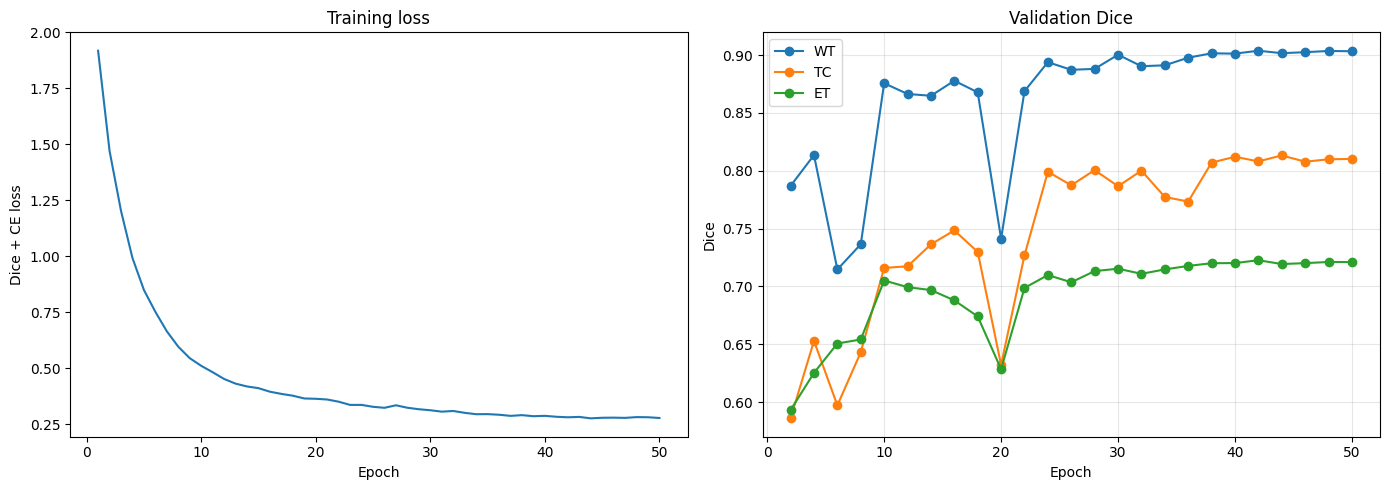

In [18]:
ck = torch.load(f"{ckpt_dir}/last.pt", map_location="cpu")
hist = ck["history"]
vh = [h for h in hist if "WT" in h]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot([h["epoch"] + 1 for h in hist], [h["loss"] for h in hist])
ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Dice + CE loss")

for r in ["WT", "TC", "ET"]:
    ax[1].plot([h["epoch"] + 1 for h in vh], [h[r] for h in vh], marker="o", label=r)
ax[1].set_title("Validation Dice"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Dice")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{ckpt_dir}/training_curves.png", dpi=150)
plt.show()

In [19]:
import pandas as pd

model = UNet3D().to(device)
model.load_state_dict(torch.load(f"{ckpt_dir}/best_model.pt", map_location=device))

test_ds = BraTSDataset(test_ids, train=False)
test_dl = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=2)

@torch.no_grad()
def evaluate(model, loader, ids):
    model.eval()
    rows = []
    for (x, y), p in zip(loader, ids):
        with torch.autocast("cuda", dtype=torch.float16):
            pred = model(x.to(device)).argmax(dim=1)[0].cpu().numpy()
        y = y[0].numpy()
        row = {"patient": p}
        for r, labels in REGIONS.items():
            row[r] = dice_score(np.isin(pred, labels), np.isin(y, labels))
        row["has_ET"] = bool(np.isin(y, [3]).any())
        rows.append(row)
    return pd.DataFrame(rows)

df = evaluate(model, test_dl, test_ids)
print(df[["WT", "TC", "ET"]].agg(["mean", "std", "median", "min", "max"]).round(3))
print("\nPatients without ET in ground truth:", (~df["has_ET"]).sum())
print("Patients with ET Dice = 0:", (df["ET"] == 0).sum())

df.to_csv(f"{ckpt_dir}/test_results.csv", index=False)
print("\n✅ Saved test_results.csv to Drive")

           WT     TC     ET
mean    0.880  0.786  0.713
std     0.098  0.221  0.254
median  0.903  0.859  0.806
min     0.383  0.076  0.000
max     0.975  0.983  0.973

Patients without ET in ground truth: 2
Patients with ET Dice = 0: 3

✅ Saved test_results.csv to Drive


In [20]:
pd.set_option("display.width", 120)

print("=== ET Dice = 0 ===")
print(df[df["ET"] == 0].round(3))

print("\n=== Patients without ET ===")
print(df[~df["has_ET"]].round(3))

print("\n=== Worst 5 by TC ===")
print(df.sort_values("TC").head(5).round(3))

=== ET Dice = 0 ===
                 patient     WT     TC   ET  has_ET
7   BraTS20_Training_275  0.383  0.087  0.0   False
11  BraTS20_Training_310  0.898  0.876  0.0   False
55  BraTS20_Training_328  0.841  0.660  0.0    True

=== Patients without ET ===
                 patient     WT     TC   ET  has_ET
7   BraTS20_Training_275  0.383  0.087  0.0   False
11  BraTS20_Training_310  0.898  0.876  0.0   False

=== Worst 5 by TC ===
                 patient     WT     TC     ET  has_ET
46  BraTS20_Training_280  0.837  0.076  0.312    True
7   BraTS20_Training_275  0.383  0.087  0.000   False
52  BraTS20_Training_141  0.890  0.230  0.132    True
37  BraTS20_Training_259  0.864  0.240  0.502    True
29  BraTS20_Training_113  0.954  0.346  0.748    True


In [21]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, gts = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            pred = model(x.to(device)).argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
        preds.append(pred)
        gts.append(y[0].numpy().astype(np.uint8))
    return preds, gts

def postprocess(pred, T):
    pred = pred.copy()
    if np.sum(pred == 3) < T:
        pred[pred == 3] = 1          # chinna ET → necrotic (TC, WT maaraadhu)
    return pred

def mean_dice(preds, gts, T):
    out = {}
    for r, labels in REGIONS.items():
        out[r] = np.mean([dice_score(np.isin(postprocess(p, T), labels), np.isin(g, labels))
                          for p, g in zip(preds, gts)])
    return out

val_preds, val_gts = predict_all(model, val_dl)

print("  T   |   WT    TC    ET")
for T in [0, 50, 100, 200, 500, 1000, 2000]:
    d = mean_dice(val_preds, val_gts, T)
    print(f"{T:5d} | {d['WT']:.3f} {d['TC']:.3f} {d['ET']:.3f}")

  T   |   WT    TC    ET
    0 | 0.903 0.810 0.721
   50 | 0.903 0.810 0.721
  100 | 0.903 0.810 0.721
  200 | 0.903 0.810 0.739
  500 | 0.903 0.810 0.770
 1000 | 0.903 0.810 0.770
 2000 | 0.903 0.810 0.749


In [22]:
BEST_T = 500    # validation-la choose pannadhu

test_preds, test_gts = predict_all(model, test_dl)

rows = []
for p, g, pid in zip(test_preds, test_gts, test_ids):
    pp = postprocess(p, BEST_T)
    row = {"patient": pid}
    for r, labels in REGIONS.items():
        row[r] = dice_score(np.isin(pp, labels), np.isin(g, labels))
    rows.append(row)
df_pp = pd.DataFrame(rows)

print("=== BEFORE post-processing ===")
print(df[["WT", "TC", "ET"]].agg(["mean", "std", "median"]).round(3))
print("\n=== AFTER post-processing (T = 500) ===")
print(df_pp[["WT", "TC", "ET"]].agg(["mean", "std", "median"]).round(3))
print("\nET = 0 patients:", (df["ET"] == 0).sum(), "→", (df_pp["ET"] == 0).sum())

df_pp.to_csv(f"{ckpt_dir}/test_results_postprocessed.csv", index=False)
print("\n✅ Saved")

=== BEFORE post-processing ===
           WT     TC     ET
mean    0.880  0.786  0.713
std     0.098  0.221  0.254
median  0.903  0.859  0.806

=== AFTER post-processing (T = 500) ===
           WT     TC     ET
mean    0.880  0.786  0.711
std     0.098  0.221  0.260
median  0.903  0.859  0.806

ET = 0 patients: 3 → 4

✅ Saved


In [23]:
cmp = pd.DataFrame({
    "patient": test_ids,
    "ET_before": df["ET"].values,
    "ET_after": df_pp["ET"].values,
    "pred_ET_voxels": [int(np.sum(p == 3)) for p in test_preds],
    "true_ET_voxels": [int(np.sum(g == 3)) for g in test_gts],
})
print("=== Changed patients ===")
print(cmp[cmp["ET_before"].round(4) != cmp["ET_after"].round(4)].round(3))
print("\n=== 275, 310, 328 ===")
print(cmp[cmp["patient"].isin(["BraTS20_Training_275", "BraTS20_Training_310", "BraTS20_Training_328"])].round(3))

=== Changed patients ===
                 patient  ET_before  ET_after  pred_ET_voxels  true_ET_voxels
52  BraTS20_Training_141      0.132       0.0              50             708

=== 275, 310, 328 ===
                 patient  ET_before  ET_after  pred_ET_voxels  true_ET_voxels
7   BraTS20_Training_275        0.0       0.0            3958               0
11  BraTS20_Training_310        0.0       0.0            5941               0
55  BraTS20_Training_328        0.0       0.0             730            1036
